# 01 — Pulizia dei dati

Obiettivo: partire da `data/processed/trento_merged.csv` (DPC + mobilità Google, P.A. Trento) e produrre un dataset pulito per il fitting del SEIRD.

Passi:
1. Cercare le anomalie nelle colonne cumulative (cali e salti improvvisi)
2. Capire da dove vengono
3. Correggerle ridistribuendo la revisione sul periodo a cui si riferisce
4. Confrontare dati originali e corretti
5. Controllare la mobilità
6. Salvare `data/processed/trento_clean.csv`

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from seird_gp.data import PROCESSED_DIR, build_merged_dataset
from seird_gp.cleaning import CUMULATIVE, KNOWN_REVISIONS, apply_revisions, to_daily

path = PROCESSED_DIR / "trento_merged.csv"
raw = pd.read_csv(path, index_col=0, parse_dates=True) if path.exists() else build_merged_dataset()
print(f"{len(raw)} giorni, dal {raw.index.min().date()} al {raw.index.max().date()}")
raw.head()

965 giorni, dal 2020-02-24 al 2022-10-15


,totale_positivi,dimessi_guariti,deceduti,totale_casi,retail_and_recreation,grocery_and_pharmacy,parks,transit_stations,workplaces,residential
data,,,,,,,,,,
2020-02-24,0,0,0,0,10.0,29.0,46.0,-3.0,-19.0,4.0
2020-02-25,0,0,0,0,-1.0,13.0,14.0,-11.0,-22.0,8.0
2020-02-26,0,0,0,0,-4.0,1.0,-7.0,-17.0,-15.0,7.0
2020-02-27,0,0,0,0,0.0,3.0,8.0,-13.0,-15.0,6.0
2020-02-28,0,0,0,0,0.0,1.0,19.0,-10.0,-14.0,6.0


## 1. Ricerca delle anomalie

`dimessi_guariti`, `deceduti` e `totale_casi` sono **cumulativi**: non possono scendere, e un salto molto più grande dei giorni vicini è sospetto.

Vale anche l'identità `totale_positivi = totale_casi − dimessi_guariti − deceduti`, che controlliamo.

In [2]:
rows = []
for col in CUMULATIVE:
    d = raw[col].diff()
    typical = d.rolling(15, center=True, min_periods=1).median().abs()
    mask = (d < 0) | ((d > 8 * typical + 20) & (d > 3 * d.rolling(31, center=True, min_periods=1).mean()))
    rows += [(day.date(), col, int(v)) for day, v in d[mask].items()]
anomalies = pd.DataFrame(rows, columns=["data", "colonna", "variazione giornaliera"])
print("Identità positivi rispettata:",
      (raw.totale_positivi == raw.totale_casi - raw.dimessi_guariti - raw.deceduti).all())
anomalies

Identità positivi rispettata: True


,data,colonna,variazione giornaliera
0,2020-05-22,dimessi_guariti,-531
1,2020-06-24,dimessi_guariti,447
2,2020-06-24,deceduti,-61
3,2020-06-24,totale_casi,387


## 2. Da dove vengono

**24/06/2020 — decessi −61, guariti +447, casi +387.** Quel giorno il Ministero della Salute ha allineato i due flussi di dati (quello quotidiano della Protezione Civile e la sorveglianza ISS) e uniformato la definizione di caso. Trento ha ricalcolato i totali: 61 decessi tolti, 447 guariti e 387 casi aggiunti. Non sono eventi di quel giorno ma correzioni di tutta la prima ondata. Fonte: [Fanpage, 24/06/2020](https://www.fanpage.it/attualita/perche-con-lultimo-bollettino-e-diminuito-il-numero-di-morti-per-coronavirus/).

**22/05/2020 — guariti −531.** In un giorno circa 530 persone passano da guariti a positivi (i positivi salgono da 66 a 607). Non ho trovato una nota ufficiale. L'ipotesi più plausibile è che nelle settimane prima i guariti fossero conteggiati in anticipo, e il 22/05 la Provincia abbia riallineato. I positivi a 66 il 21/05 sono comunque troppo bassi rispetto al trend.

**24/01/2021 — decessi +30.** Non supera la soglia automatica, ma è documentato nelle note DPC (`note/dpc-covid19-ita-note.csv`): 30 decessi avvenuti in due RSA a novembre-dicembre 2020 e conteggiati solo quel giorno.

In [3]:
pd.DataFrame([vars(r) for r in KNOWN_REVISIONS])

,date,column,amount,start,end,note
0,2020-05-22,dimessi_guariti,-531,2020-02-24,2020-05-21,Riclassificazione guariti -> positivi (causa n...
1,2020-06-24,deceduti,-61,2020-02-24,2020-06-23,Ricalcolo decessi per allineamento flussi
2,2020-06-24,dimessi_guariti,447,2020-02-24,2020-06-23,Ricalcolo guariti per allineamento flussi
3,2020-06-24,totale_casi,387,2020-02-24,2020-06-23,Ricalcolo casi per allineamento flussi
4,2021-01-24,deceduti,30,2020-11-01,2020-12-31,30 decessi RSA di nov-dic 2020 conteggiati in ...


## 3. Correzione

Per ogni revisione:
- si toglie l'importo dal giorno in cui è comparso;
- lo si ridistribuisce sul periodo a cui si riferisce, **in proporzione agli incrementi giornalieri osservati** (es. −61 decessi sulla prima ondata: ogni giorno perde circa il 13% dei decessi riportati);
- il valore cumulativo finale non cambia.

Poi si ricalcola `totale_positivi` dall'identità, così le colonne restano coerenti tra loro.

Assunzione principale: le persone tolte o aggiunte erano distribuite nel tempo come quelle riportate. Per il 22/05 la scelta del periodo (tutta la prima ondata) è un'ipotesi.

In [4]:
clean = apply_revisions(raw)
for col in CUMULATIVE:
    print(f"{col:16s} cali residui: {(clean[col].diff() < -1e-9).sum()}   "
          f"valore finale invariato: {abs(clean[col].iloc[-1] - raw[col].iloc[-1]) < 1e-6}")
print("positivi negativi:", (clean.totale_positivi < 0).sum())

dimessi_guariti  cali residui: 0   valore finale invariato: True
deceduti         cali residui: 0   valore finale invariato: True
totale_casi      cali residui: 0   valore finale invariato: True
positivi negativi: 0


## 4. Confronto originale / corretto (prima ondata e inizio seconda)

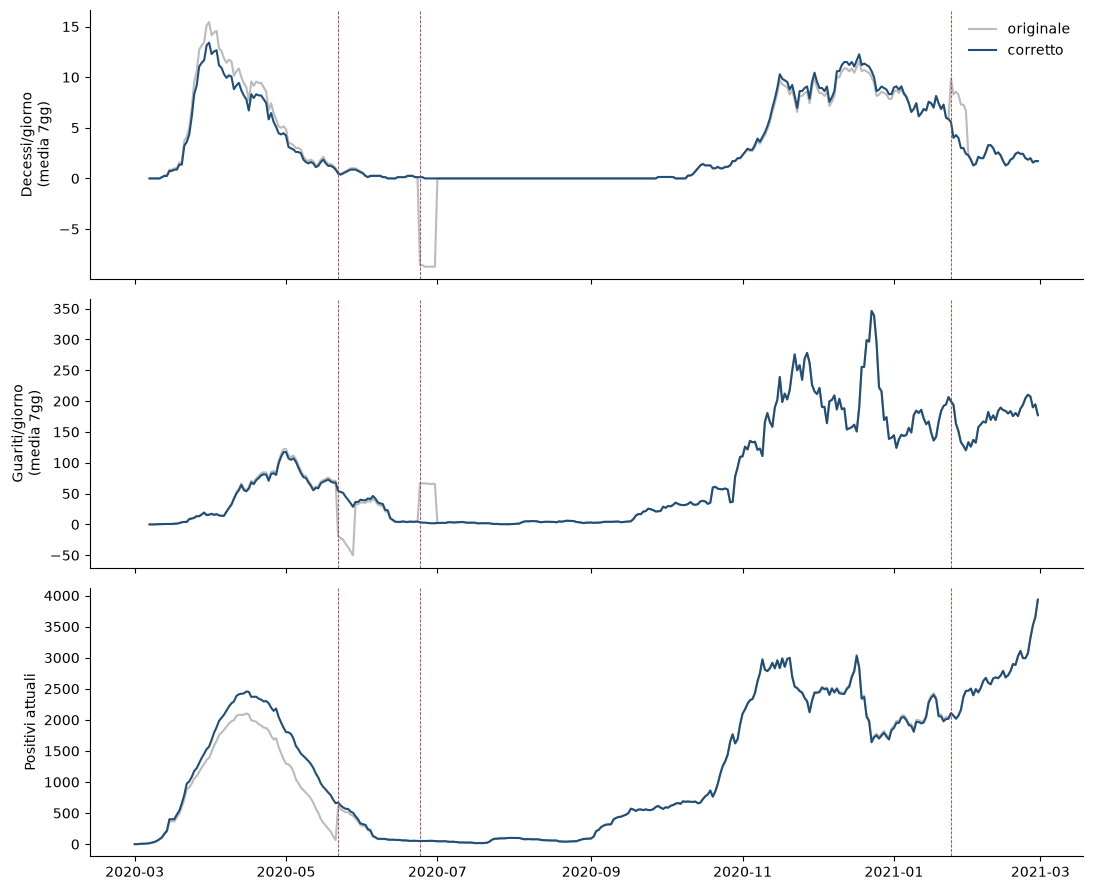

In [5]:
win = slice("2020-03-01", "2021-02-28")
fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for a, col, lab in [(ax[0], "deceduti", "Decessi/giorno"), (ax[1], "dimessi_guariti", "Guariti/giorno")]:
    a.plot(to_daily(raw[col]).loc[win].rolling(7).mean(), label="originale", color="#bbb")
    a.plot(to_daily(clean[col]).loc[win].rolling(7).mean(), label="corretto", color="#1f4e79")
    a.set_ylabel(lab + "\n(media 7gg)")
ax[2].plot(raw.totale_positivi.loc[win], label="originale", color="#bbb")
ax[2].plot(clean.totale_positivi.loc[win], label="corretto", color="#1f4e79")
ax[2].set_ylabel("Positivi attuali")
for d in ["2020-05-22", "2020-06-24", "2021-01-24"]:
    for a in ax: a.axvline(pd.Timestamp(d), color="#a33", lw=0.6, ls="--")
ax[0].legend(frameon=False)
for a in ax: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

Effetto sulle finestre usate da Pianesi e Pojer (che hanno usato i dati originali):

In [6]:
windows = {"1/3–1/4/2020": ("2020-03-01", "2020-04-01"),
           "1/3–1/6/2021": ("2021-03-01", "2021-06-01"),
           "1/1–1/3/2022": ("2022-01-01", "2022-03-01")}
summary = []
for name, (a, b) in windows.items():
    for col in ["deceduti", "totale_positivi"]:
        r, c = raw.loc[a:b, col], clean.loc[a:b, col]
        summary.append((name, col, int(r.iloc[-1]), round(c.iloc[-1]), f"{(c - r).abs().max():.0f}"))
pd.DataFrame(summary, columns=["finestra", "colonna", "originale (fine)", "corretto (fine)", "diff. max"])

,finestra,colonna,originale (fine),corretto (fine),diff. max
0,1/3–1/4/2020,deceduti,173,150,23
1,1/3–1/4/2020,totale_positivi,1483,1676,193
2,1/3–1/6/2021,deceduti,1358,1358,0
3,1/3–1/6/2021,totale_positivi,480,480,0
4,1/1–1/3/2022,deceduti,1521,1521,0
5,1/1–1/3/2022,totale_positivi,3323,3323,0


## 5. Mobilità

Solo `parks` ha valori mancanti. Gli indici che useremo come input (workplaces, transit, retail) sono completi.

In [7]:
from seird_gp.data import MOBILITY_COLUMNS
print(clean[MOBILITY_COLUMNS].isna().sum())
clean.loc[clean.parks.isna()].index.date

retail_and_recreation    0
grocery_and_pharmacy     0
parks                    5
transit_stations         0
workplaces               0
residential              0
dtype: int64


array([datetime.date(2020, 8, 17), datetime.date(2020, 8, 18),
       datetime.date(2020, 8, 19), datetime.date(2020, 8, 20),
       datetime.date(2020, 8, 25)], dtype=object)

In [8]:
clean[["workplaces", "transit_stations", "retail_and_recreation", "residential"]].corr().round(2)

,workplaces,transit_stations,retail_and_recreation,residential
workplaces,1.00,0.58,0.50,-0.81
transit_stations,0.58,1.00,0.94,-0.85
retail_and_recreation,0.50,0.94,1.00,-0.78
residential,-0.81,-0.85,-0.78,1.00


Gli indici di mobilità fuori casa sono molto correlati tra loro: al GP conviene passarne pochi. `residential` va in senso opposto (più tempo a casa = meno mobilità).

## 6. Salvataggio

In [9]:
raw.to_csv(PROCESSED_DIR / "trento_raw.csv")      # per confronto diretto con Pianesi e Pojer
clean.to_csv(PROCESSED_DIR / "trento_clean.csv")
print("Salvati trento_raw.csv e trento_clean.csv in", PROCESSED_DIR)

Salvati trento_raw.csv e trento_clean.csv in /home/claude/seird-gp/data/processed


## Decisioni aperte

- **Periodo di ridistribuzione del 22/05/2020**: ho usato tutta la prima ondata; con una finestra più corta la correzione si concentra a maggio.
- **Quali dati per il baseline**: proposta = fittare su entrambi (`raw` per confrontarsi col paper, `clean` per il lavoro vero) e riportare la differenza.